# M10 across four seismic geologies: model recovery and waveform evidence

**Level 3 — Comparative numerical study** · 45 min · prerequisites: the M10 lesson, wave propagation, held-out evaluation, and inverse-problem non-uniqueness.


## Objectives

Compare four physically distinct seismic structures and their product FWI results on shared velocity and residual scales. Separate known synthetic truth, the independent 1-D start, fitted and withheld receivers, and the recorded negative-control verdict.


## Setup

Use the pinned notebook environment: `scripts/setup.ps1 -Notebooks` (Windows) or `scripts/setup.sh --notebooks` (Linux/macOS). Exact pins: `pip install numpy==2.2.6 scipy==1.15.2 pandas==2.2.3 matplotlib==3.10.8`. This lesson inspects committed product runs; it does not train or re-run FWI.


In [1]:
# Print exact package versions and set this notebook's display language.
SPANISH = False
from importlib.metadata import version
for package in ("numpy", "scipy", "pandas", "matplotlib"):
    print(f"{package}=={version(package)}")


numpy==2.2.6
scipy==1.15.2
pandas==2.2.3
matplotlib==3.10.8


Verify catalogued artifact identity before interpreting its arrays.


In [2]:
# Verify exact catalogued bytes before reading the four product results.
import hashlib, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"data/derived/v2/catalog.json").is_file())
catalog = json.loads((root/"data/derived/v2/catalog.json").read_text(encoding="utf-8"))
case_ids = ["FWI_LAYERED", "FWI_FAULT", "FWI_CYCLE_SKIP", "FWI_NOISY"]
records = {}
for cid in case_ids:
    entry = next(c for c in catalog["cases"] if c["id"] == cid)
    ref = next(v for v in entry["variants"] if v["id"] == "reference")
    raw = (root/"data/derived/v2"/ref["path"]).read_bytes()
    assert len(raw) == ref["bytes"] and hashlib.sha256(raw).hexdigest() == ref["sha256"]
    run = json.loads(raw)
    assert run["id"] == cid and run["variant"] == "reference"
    assert set(run["methods"]) == {"fwi-l2", "fwi-multiscale"}
    records[cid] = run
rows = []
for cid, run in records.items():
    full, multi = run["methods"]["fwi-l2"], run["methods"]["fwi-multiscale"]
    rows.append({"Case": run["name"], "Geometry": run["geometry"], "Verdict": multi["evaluation"]["status"],
      "Start RMSE m/s": multi["metrics"]["initial_velocity_rmse"], "Full band / start": full["metrics"]["model_rmse_ratio"],
      "Continuation / start": multi["metrics"]["model_rmse_ratio"], "Fit WRMS": multi["metrics"]["active_wrms"],
      "Held-out WRMS": multi["metrics"]["withheld_wrms"]})
table = pd.DataFrame(rows).round(3)
if SPANISH:
    table = table.rename(columns={"Case":"Caso", "Geometry":"Geometría", "Verdict":"Veredicto", "Start RMSE m/s":"RMSE inicial m/s", "Full band / start":"Banda completa / inicio", "Continuation / start":"Continuación / inicio", "Fit WRMS":"WRMS ajustado", "Held-out WRMS":"WRMS retenido"})
display(table)
print("Cuatro hashes de bytes del catálogo verificados. Observaciones e inversión usan el mismo motor directo sintético." if SPANISH else "Four catalogued byte hashes verified. Observations and inverse use the same synthetic forward engine.")
print("Todos los casos retienen receptores con índice módulo cinco igual a dos; las trazas retenidas no seleccionan estados del optimizador." if SPANISH else "All cases hold out receiver indices modulo five equal to two; held-out traces never select an optimizer state.")


,Case,Geometry,Verdict,Start RMSE m/s,Full band / start,Continuation / start,Fit WRMS,Held-out WRMS
0,Layered reflection survey,layers,recovered,229.095,0.535,0.527,1.208,1.233
1,Normal fault displacement,normal_fault,recovered,301.203,0.701,0.653,1.340,1.388
2,Salt dome / cycle skipping,salt,negative-control,726.036,0.852,0.803,1.751,1.966
3,Low-velocity gas channel,channel,unresolved,340.618,0.660,0.521,2.071,2.213


Four catalogued byte hashes verified. Observations and inverse use the same synthetic forward engine.
All cases hold out receiver indices modulo five equal to two; held-out traces never select an optimizer state.


## Data

Four byte-verified reference runs represent layered reflection, a displaced normal fault, salt-dome cycle skipping, and a low-velocity channel. Observations are synthetic and share the inversion's forward engine with independent additive noise. That inverse-crime limitation is retained.


## Method

Each artifact stores the true model, an independent depth-trend start, three-shot observed data, a fixed receiver holdout, and full-band plus frequency-continuation product inversions. The product uses Deepwave acoustic pressure propagation and L-BFGS with physically scaled velocity-gradient roughness. Methods share their case's acquisition, start, noise, and four spatial control grids. The plotted residual gather is observed minus predicted; horizontal marks identify withheld receivers.


## Comparison

Low-to-high frequency continuation is a standard approach to cycle skipping: low frequencies reduce phase ambiguity before higher frequencies refine detail. It does not guarantee convergence or uniqueness. This matrix is not an independent propagator comparison or field-generalization study.


## Results

The table reports model RMSE relative to the independent start, fitted WRMS, and receiver-held-out WRMS. All four distinct structures share one 1,400–4,400 m/s model scale and one signed residual scale. Salt remains a negative control; do not average its failure into a success verdict. A model-RMSE ratio below one means improvement over the declared start for that synthetic realization only.


Compare distinct targets and residual gathers with held-out receivers marked.


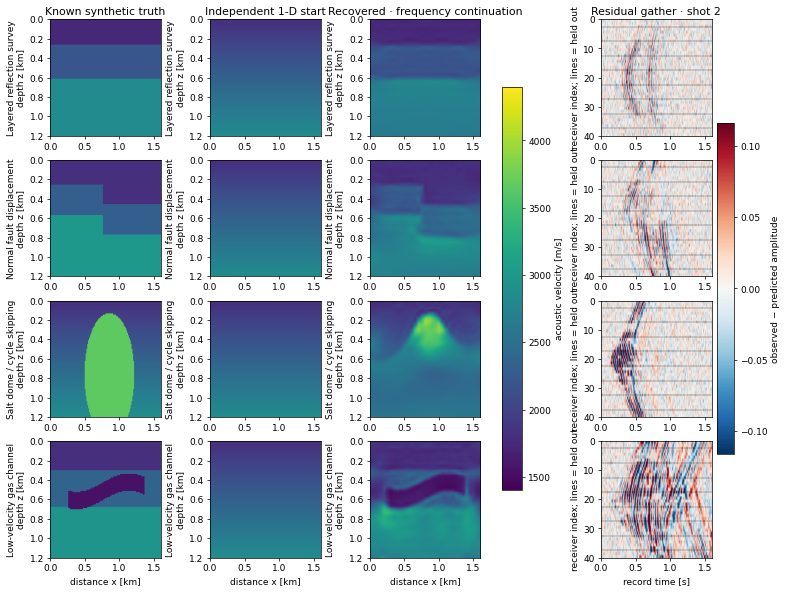

In [3]:
# Put four different geological targets and their measured residual gathers on common scales.
fig, axes = plt.subplots(4, 4, figsize=(12, 9), dpi=65, constrained_layout=True)
gathers = [np.asarray(records[c]["methods"]["fwi-multiscale"]["residual"])[1] for c in case_ids]
limit = float(np.quantile(np.concatenate([np.abs(g).ravel() for g in gathers]), .98))
im = None
for i, cid in enumerate(case_ids):
    run = records[cid]
    models = [np.asarray(run["truth"]), np.asarray(run["initial"]), np.asarray(run["methods"]["fwi-multiscale"]["model"])]
    titles = ("Verdad sintética", "Inicio 1D independiente", "Recuperado · continuación") if SPANISH else ("Known synthetic truth", "Independent 1-D start", "Recovered · frequency continuation")
    for j, (arr, title) in enumerate(zip(models, titles)):
        ax=axes[i,j]; im=ax.imshow(arr,origin="upper",aspect="auto",extent=(0,1.6,1.2,0),cmap="viridis",vmin=1400,vmax=4400)
        if i==0: ax.set_title(title)
        ax.set_ylabel(f"{run['name']}\nprofundidad z [km]" if SPANISH else f"{run['name']}\ndepth z [km]")
        if i==3: ax.set_xlabel("distancia x [km]" if SPANISH else "distance x [km]")
    ax=axes[i,3]; res=gathers[i]
    ax.imshow(res,origin="upper",aspect="auto",extent=(0,res.shape[1]*.004,res.shape[0],0),cmap="RdBu_r",vmin=-limit,vmax=limit)
    for r in np.flatnonzero(~np.asarray(run["active_receivers"],dtype=bool)): ax.axhline(r+.5,color="#111",lw=.35)
    if i==0: ax.set_title("Registro residual · disparo 2" if SPANISH else "Residual gather · shot 2")
    ax.set_ylabel("índice de receptor; líneas = retenidos" if SPANISH else "receiver index; lines = held out")
    if i==3: ax.set_xlabel("tiempo [s]" if SPANISH else "record time [s]")
fig.colorbar(im,ax=axes[:,:3],label="velocidad acústica [m/s]" if SPANISH else "acoustic velocity [m/s]",shrink=.75)
fig.colorbar(axes[0,3].images[0],ax=axes[:,3],label="amplitud observada − predicha" if SPANISH else "observed − predicted amplitude",shrink=.75)
plt.show()


Read case-level recovery ratios and noise-consistency diagnostics.


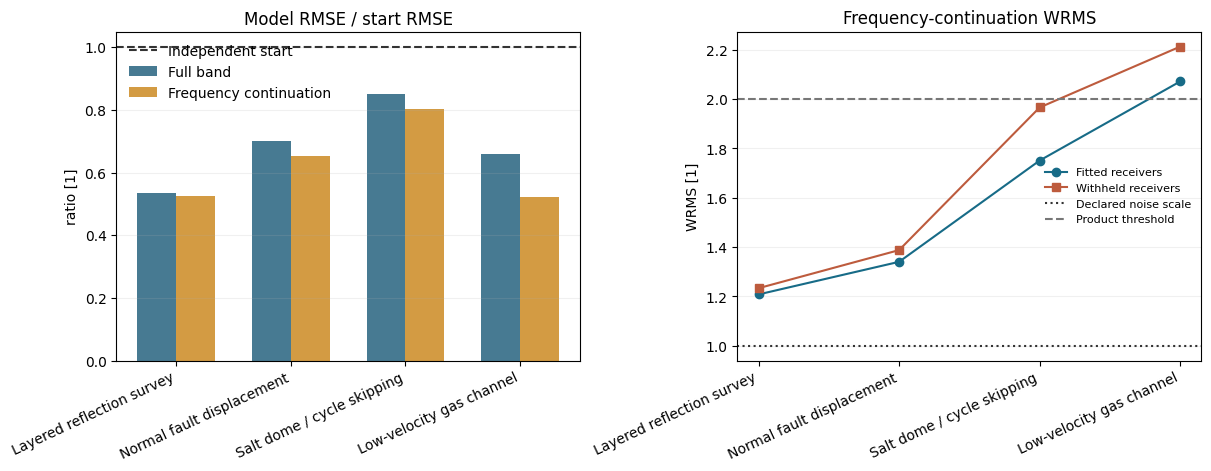

FWI_LAYERED verdict recovered reasons []
FWI_FAULT verdict recovered reasons []
FWI_CYCLE_SKIP verdict negative-control reasons ['salt_cycle_skipping_challenge']
FWI_NOISY verdict unresolved reasons ['active_data_misfit_above_declared_noise', 'withheld_data_misfit_above_declared_noise']


In [4]:
# Compare both inversions to the declared start and inspect the held-out noise scale.
fig, axes = plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)
x=np.arange(len(case_ids)); w=.34
full=[records[c]["methods"]["fwi-l2"]["metrics"]["model_rmse_ratio"] for c in case_ids]
multi=[records[c]["methods"]["fwi-multiscale"]["metrics"]["model_rmse_ratio"] for c in case_ids]
active=[records[c]["methods"]["fwi-multiscale"]["metrics"]["active_wrms"] for c in case_ids]
held=[records[c]["methods"]["fwi-multiscale"]["metrics"]["withheld_wrms"] for c in case_ids]
names=[records[c]["name"] for c in case_ids]
axes[0].bar(x-w/2,full,w,label="Banda completa" if SPANISH else "Full band",color="#477a92"); axes[0].bar(x+w/2,multi,w,label="Continuación en frecuencia" if SPANISH else "Frequency continuation",color="#d39b43")
axes[0].axhline(1,color="#333",ls="--",label="Inicio independiente" if SPANISH else "Independent start"); axes[0].set(title="RMSE del modelo / RMSE inicial" if SPANISH else "Model RMSE / start RMSE",ylabel="razón [1]" if SPANISH else "ratio [1]"); axes[0].legend(frameon=False)
axes[1].plot(x,active,"o-",label="Receptores ajustados" if SPANISH else "Fitted receivers",color="#176b87"); axes[1].plot(x,held,"s-",label="Receptores retenidos" if SPANISH else "Withheld receivers",color="#bd5b3d")
axes[1].axhline(1,color="#333",ls=":",label="Escala de ruido declarada" if SPANISH else "Declared noise scale"); axes[1].axhline(2,color="#777",ls="--",label="Umbral del producto" if SPANISH else "Product threshold")
axes[1].set(title="WRMS con continuación de frecuencia" if SPANISH else "Frequency-continuation WRMS",ylabel="WRMS [1]"); axes[1].legend(frameon=False,fontsize=8)
for ax in axes: ax.set_xticks(x,names,rotation=25,ha="right"); ax.grid(axis="y",alpha=.18)
plt.show()
for cid in case_ids:
    m=records[cid]["methods"]["fwi-multiscale"]
    print(cid, "verdict", m["evaluation"]["status"], "reasons", m["evaluation"]["reason_codes"])


## Summary

Four synthetic cases are not four independent field validations. Receiver holdout samples the same aperture, and observations and inversion share a forward engine. Better model or data scores do not establish unique geology, field transfer, or calibrated uncertainty. Read the salt failure and the distinct fault/channel patterns alongside the aggregate metrics.


## References

- [Devito full-waveform inversion tutorial](https://www.devitoproject.org/examples/seismic/tutorials/03_fwi.html) — primary-source formulation context; the computed runs use the repository's pinned Deepwave engine.
- [M10 acoustic FWI method and limits](../../../docs/problem-types/02_fwi-recovery.md).
